# 04 - Campaign Targeting Policy and Business Recommendation

Simulates and offline-evaluates 7 targeting policies (treat all / none / random / positive-uplift / top-10%
/ top-20% / validation-selected top-K). The original model holdout is split into policy-validation and
policy-test halves. Model/coverage selection uses validation outcomes only; fixed policies are evaluated
once on untouched test outcomes with Inverse Propensity Scoring and profit confidence intervals.

In [1]:
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
from src.utils.config import TABLES_DIR, FIGURES_DIR, REPORT_DIR

## Validation-Set Model Selection

In [2]:
pd.read_csv(TABLES_DIR / "policy_model_selection_validation.csv")

,model,qini_coefficient,auuc_score,qini_per_100k,auuc_per_100k,average_predicted_uplift
0,S-Learner,173.345071,174.428855,38.521127,38.761968,0.000907
1,DR-Learner,169.070819,166.017219,37.571293,36.892715,0.000990
2,Causal Forest,146.983481,151.561105,32.662996,33.680245,0.000960
3,X-Learner,121.264120,117.805530,26.947582,26.179007,0.001015
4,T-Learner,101.114520,96.231382,22.469893,21.384751,0.001023


## Policy Comparison

In [3]:
pd.read_csv(TABLES_DIR / "policy_comparison.csv")

,policy,coverage,n_targeted,expected_conversion_rate,expected_conversions,incremental_conversions_vs_treat_none,incremental_conversions_se,campaign_cost,incremental_revenue,net_profit,net_profit_ci_low,net_profit_ci_high,profit_per_contact
0,Top-K Selected on Validation,0.020002,9001,0.002679,1205.490413,258.822694,70.783129,4500.5,12941.134717,8440.634717,1504.015516,15377.253918,0.937744
1,Treat None,0.000000,0,0.002104,946.667719,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,NaN
2,Top 10% Uplift,0.100002,45001,0.002960,1332.156776,385.489057,82.657724,22500.5,19274.452866,-3226.047134,-11326.355216,4874.260947,-0.071688
3,Top 20% Uplift,0.200002,90001,0.002957,1330.588053,383.920334,86.055925,45000.5,19196.016715,-25804.483285,-34237.808988,-17371.157582,-0.286713
4,Random 50%,0.500486,225219,0.002705,1217.255352,270.587633,60.102479,112609.5,13529.381661,-99080.118339,-104970.053043,-93190.183635,-0.439928
5,Positive Uplift Only,0.961140,432514,0.003019,1358.431141,411.763423,87.748326,216257.0,20588.171127,-195668.828873,-204268.006793,-187069.650954,-0.452399
6,Treat All,1.000000,450001,0.003056,1375.293848,428.626129,89.043399,225000.5,21431.306473,-203569.193527,-212295.286297,-194843.100756,-0.452375


## Profit-Maximizing Targeting Curve

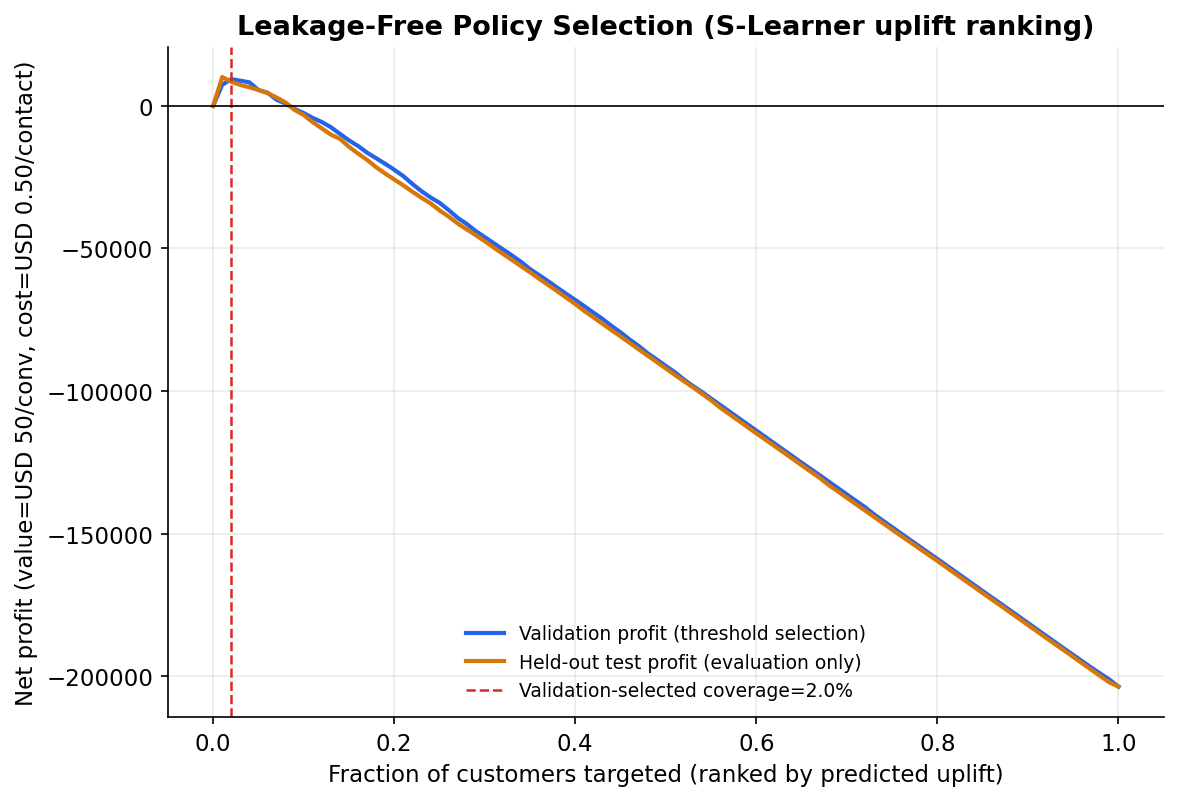

In [4]:
display(Image(filename=str(FIGURES_DIR / "profit_maximizing_curve.png")))

## Cost / Value Sensitivity

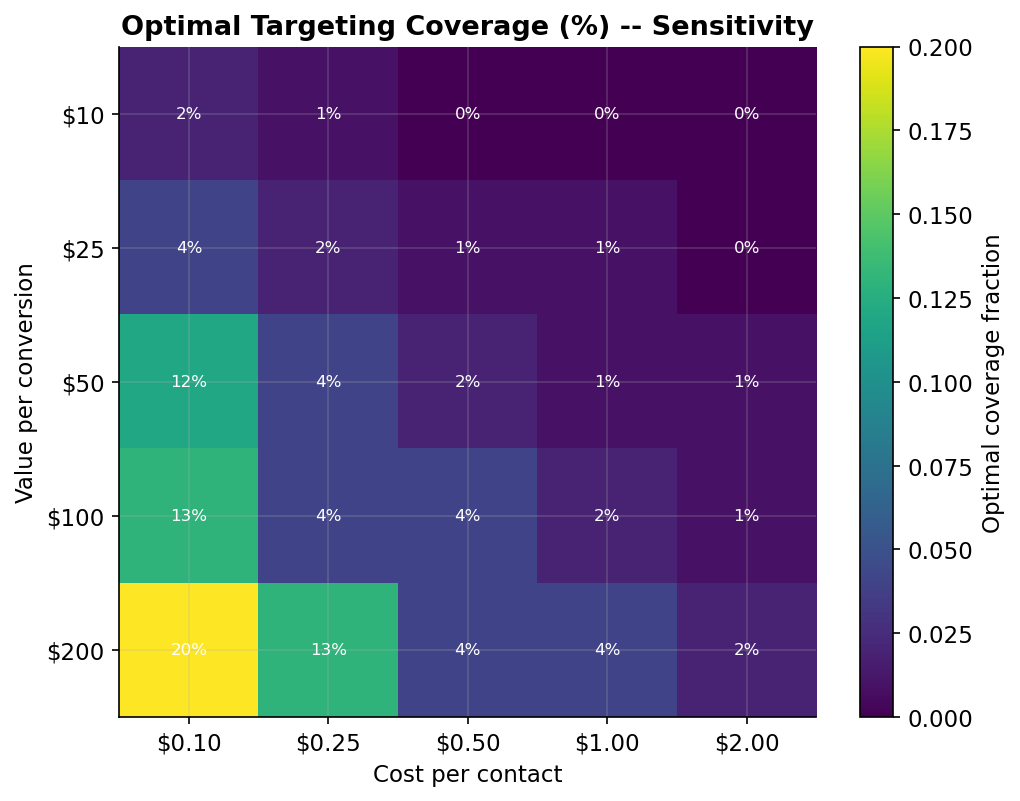

In [5]:
display(Image(filename=str(FIGURES_DIR / "cost_sensitivity_heatmap.png")))

In [6]:
pd.read_csv(TABLES_DIR / "cost_sensitivity_sweep.csv")

,value_per_conversion,cost_per_contact,selected_coverage_validation,selection_profit_validation,evaluation_profit_test,evaluation_profit_ci_low_test,evaluation_profit_ci_high_test
0,10.0,0.10,0.02,1872.540981,1688.126943,300.803103,3075.450784
1,10.0,0.25,0.01,804.405373,1345.331738,121.588849,2569.074627
2,10.0,0.50,0.00,0.000000,0.000000,0.000000,0.000000
3,10.0,1.00,0.00,0.000000,0.000000,0.000000,0.000000
4,10.0,2.00,0.00,0.000000,0.000000,0.000000,0.000000
5,25.0,0.10,0.04,6817.623800,5944.973427,2179.122864,9710.823990
6,25.0,0.25,0.02,4681.352454,4220.317359,752.007758,7688.626959
7,25.0,0.50,0.01,2573.513433,3925.954344,866.597122,6985.311567
8,25.0,1.00,0.01,323.513433,1675.454344,-1383.902878,4734.811567
9,25.0,2.00,0.00,0.000000,0.000000,0.000000,0.000000


## Ablation Study & Final Business Recommendation

In [7]:
import json
ablation = json.loads((REPORT_DIR / "phase3_ablation.json").read_text())
ablation["profit_maximizing_summary"]

{'selected_coverage_validation': 0.02,
 'selected_customers_validation': 9000,
 'selection_profit_validation': 9362.70490709776,
 'targeted_customers_test': 9001,
 'evaluation_profit_test': 8440.634717427378,
 'evaluation_profit_ci_low_test': 1504.015516369187,
 'evaluation_profit_ci_high_test': 15377.253918485569}

Validation selects S-Learner and a 2% targeting rate. Applying that fixed rule once to the untouched policy
test set yields positive estimated profit, while treating everyone is unprofitable under the stated value
and contact-cost assumptions. These figures are scenario results rather than observed accounting outcomes.